# Six-panel East River basin figure

Terrain, optical imagery, canopy cover, snow-cover change, SNODAS snowmelt and NISAR coherence for one NISAR pair (2026-02-27 to 2026-03-11), all on the 80 m NISAR grid (UTM 13N).

Every choice (dates, colormaps, color limits, layout, titles, thresholds, file names) lives in the **Style settings** cells, so you can change the figure without touching the plotting code.

In [2]:
import gzip
import tarfile
import requests
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401
import geopandas as gpd
import shapely
import pystac_client
import planetary_computer as pc
import odc.stac
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource, Normalize, ListedColormap, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from pyproj import Transformer
from rasterio import features
from rasterio.enums import Resampling
from shapely.geometry import shape
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.fsca import classify_fsca, classify_change, change_labels

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we setup logging to get useful information and error messages.

In [3]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True
)

# Style settings

Everything you are likely to want to tweak is in this section. Colors can be any matplotlib color (name, hex, RGB tuple) and colormaps any matplotlib colormap name. Sizes of text are in points, distances on the map are in meters.

## General

In [4]:
data_dir = "../data/"
out_dir = "../outputs/figures/"

SAVE_FIGS = True            # if True, the figure is written to out_dir as a PNG
FIG_NAME = 'ndseg_six_panel.png'
FIG_DPI = 300               # resolution of the saved figure

SAVE_LAYERS = True          # if True, the aligned 80 m layers are written as a Zarr and as GeoTIFFs
LAYERS_ZARR = '../outputs/ndseg_figure_layers.zarr'
LAYERS_TIF_DIR = '../outputs/ndseg_figure_layers/'

# NISAR cube (the 80 m grid every panel is placed on)
track, frame = 19, 21
PAIR = '20260227_20260311'  # NISAR pair, as '<start>_<end>' (must exist in snow_80m.zarr)

## Basin outline

The basin is the footprint of the pixels with a valid elevation in the NISAR 80 m cube. The raw pixel mask is cleaned up a little (gaps closed, small specks dropped, edges simplified) so it draws as a smooth line.

In [5]:
MASK_TO_BASIN = True        # if True, pixels outside the basin are left blank in every panel
BASIN_CLOSE_M = 200         # close gaps / holes narrower than ~2x this distance (m)
BASIN_MIN_AREA_KM2 = 1      # drop disconnected pieces smaller than this (km^2)
BASIN_SIMPLIFY_M = 40       # simplify tolerance for the outline (m)

# a white halo under a dark line stays visible on any background; set BASIN_HALO to None for no halo
BASIN_STYLE = dict(edgecolor='black', linewidth=1.2)
BASIN_HALO = dict(edgecolor='white', linewidth=2.6, alpha=0.7)

## Panel 1: DEM and hillshade

In [6]:
DEM_CMAP = 'gist_earth'         # any matplotlib colormap, e.g. 'gist_earth', 'cividis', 'Greys_r'
DEM_VMIN, DEM_VMAX = None, None # elevation color limits (m); None = data min/max
DEM_CBAR_LABEL = 'Elevation (m)'

HILLSHADE_AZIMUTH = 315         # direction of the light (degrees clockwise from north)
HILLSHADE_ALTITUDE = 45         # sun angle above the horizon (degrees)
HILLSHADE_VERT_EXAG = 1.0       # vertical exaggeration; raise to emphasize relief
HILLSHADE_STRENGTH = 0.6        # 0 = no hillshade, 1 = full
HILLSHADE_BLEND = 'soft'        # matplotlib blend mode: 'soft', 'overlay' or 'hsv'

## Panel 2: Sentinel-2 true color

Scenes are searched on the Microsoft Planetary Computer STAC (Sentinel-2 L2A). All scenes on `S2_DATE` with a cloud cover below `S2_MAX_CLOUD` are mosaicked, since the basin straddles two tiles.

In [7]:
S2_DATE = '2026-03-11'
S2_MAX_CLOUD = 30               # scene-level cloud cover limit (%)
S2_STAC_URL = 'https://planetarycomputer.microsoft.com/api/stac/v1'
S2_COLLECTION = 'sentinel-2-l2a'
S2_BANDS = ('B04', 'B03', 'B02')   # red, green, blue
S2_LOAD_RES = 20                # resolution (m) the bands are loaded at before averaging down to 80 m
S2_DN_OFFSET = -1000            # L2A processing baseline >= 04.00 adds +1000 to the digital numbers
S2_DN_SCALE = 1e-4              # digital number -> reflectance
S2_STRETCH = (0.0, 0.7)         # reflectance mapped to black and white (snow is ~0.6-0.9, so keep the top high)
S2_GAMMA = 1.0                  # < 1 brightens midtones
S2_CACHE = data_dir + 'sentinel2/'

## Panel 3: NLCD tree canopy

In [8]:
CANOPY_VAR = 'canopy_2019'      # NLCD canopy variable stored in snow_80m.zarr
CANOPY_CMAP = 'Greens'
CANOPY_VMIN, CANOPY_VMAX = 0, 100
CANOPY_CBAR_LABEL = 'NLCD tree canopy cover (%)'

## Panel 4: fSCA snow cover change

SPIRES fSCA is classified into snow classes (`FSCA_BINS` are the lower edges beyond the first class) and compared between the start and end date of `PAIR`. Change codes follow `scripts/fsca.py::classify_change`: stable classes keep their code, increases and decreases are coded by how many classes changed.

In [9]:
FSCA_ZARR = data_dir + 'fsca_spires/zarrs/erb_fsca_80m.zarr'
FSCA_BINS = (20, 70)                                    # class edges (% fSCA)
FSCA_LABELS = ('no snow', 'patchy snow', 'snow')        # one more label than bins

# one color per change code (stable classes, then increases, then decreases), same as 6_fsca.ipynb
CHANGE_COLORS = ['#d9d9d9', '#9ecae1', '#08519c', '#a1d99b', '#238b45', '#fdae6b', '#d94801']
CHANGE_LEGEND_ONLY_PRESENT = True                       # only list classes that occur in the map
CHANGE_LEGEND_KW = dict(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=7, frameon=False)

## Panel 5: SNODAS snowmelt

The daily SNODAS archive (NSIDC G02158) is downloaded once and cached. `SNODAS_VAR` picks the product from `SNODAS_VARS`; add an entry to show another one (`code` is the SNODAS product code, `scale` the integer scale factor in the file, `to_display` converts the scaled value to the displayed unit).

In [10]:
SNODAS_DATE = '2026-03-11'
SNODAS_URL = 'https://noaadata.apps.nsidc.org/NOAA/G02158/masked/{year}/{month:02d}_{mon}/SNODAS_{ymd}.tar'
SNODAS_CACHE = data_dir + 'snodas/'

SNODAS_VARS = {
    'melt_runoff': dict(code=11044, scale=1e5, to_display=1000.0, label='SNODAS snowmelt runoff (mm/day)', cmap='PuBu'),
    'swe':         dict(code=11034, scale=1e3, to_display=1000.0, label='SNODAS SWE (mm)', cmap='Blues'),
    'snow_depth':  dict(code=11036, scale=1e3, to_display=1000.0, label='SNODAS snow depth (mm)', cmap='Blues'),
    'snow_temp':   dict(code=11038, scale=1.0, to_display=1.0, label='SNODAS snowpack temperature (K)', cmap='coolwarm'),
}
SNODAS_VAR = 'melt_runoff'
SNODAS_VMIN, SNODAS_VMAX = 0, None       # color limits; None = data min / 99th percentile
SNODAS_RESAMPLING = Resampling.bilinear  # 1 km SNODAS -> 80 m grid

# Sharp dry/wet break: values below the threshold are drawn white (dry), and the colormap jumps straight to a
# mid-tone at the threshold. Set SNODAS_WET_THRESHOLD = None for a plain continuous colormap.
SNODAS_WET_THRESHOLD = 1.0               # in the displayed unit (mm/day for melt runoff)
SNODAS_WET_START = 0.5                   # position (0-1) on the product's colormap used right at the threshold; higher = darker jump
SNODAS_DRY_COLOR = 'white'

# SNODAS masked-domain grid (from the NSIDC G02158 documentation)
SNODAS_NCOLS, SNODAS_NROWS = 6935, 3351
SNODAS_ULX, SNODAS_ULY, SNODAS_RES = -124.73333333, 52.87500000, 0.00833333333
SNODAS_NODATA = -9999

## Panel 6: NISAR coherence

In [28]:
COH_VAR = 'gamma_temporal'
COH_CMAP = 'viridis'
COH_VMIN, COH_VMAX = 0, 1
COH_CBAR_LABEL = 'NISAR 80 m coherence'

## Layout and labels

In [31]:
FIGSIZE = (16, 12)
NROWS, NCOLS = 2, 3
PANEL_TITLES = [
    'DEM and hillshade',
    'Sentinel-2 true color (2026-03-11)',
    'NLCD tree canopy cover',
    'SPIRES fSCA change (2026-02-27 to 2026-03-11)',
    'SNODAS snowmelt runoff (2026-03-11)',
    'NISAR coherence (2026-02-27 to 2026-03-11)',
]
PANEL_TITLES = [
    '',
    '',
    '',
    '',
    '',
    '',
]
TITLE_SIZE = 10
PANEL_LETTERS = True            # prefix titles with (a), (b), ...
CBAR_KW = dict(shrink=0.75, pad=0.02)
AXIS_KM = True                  # label axes in km instead of m
SCALEBAR_KM = 5                 # length of the scale bar (km); None to hide it
SCALEBAR_PANELS = (0,)          # panel indices (0-5) that get a scale bar
BLANK_COLOR = 'white'           # color of pixels with no data

# Load data and build the basin outline

In [13]:
nisar_dir = data_dir + f'nisar/zarrs/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}/'
nisar = xr.open_zarr(nisar_dir + 'snow_80m.zarr').sel(pair=PAIR).load()
crs = nisar.rio.crs
start, end = pd.Timestamp(nisar['start'].values), pd.Timestamp(nisar['end'].values)
logging.info(f"Pair {PAIR}: {start.date()} to {end.date()}, grid {nisar.sizes['y']} x {nisar.sizes['x']} in {crs}")

grid = nisar['elevation']                    # reference grid and basin mask
valid = grid.notnull()

2026-10-28 11:11:51,348 - INFO - Pair 20260227_20260311: 2026-02-27 to 2026-03-11, grid 524 x 410 in EPSG:32613


In [14]:
def basin_polygon(valid, close_m, min_area_km2, simplify_m):
    """Outline of a boolean ``valid`` raster (rioxarray) as a single cleaned-up shapely geometry."""
    mask = valid.values.astype('uint8')
    polys = [shape(g) for g, v in features.shapes(mask, mask=mask.astype(bool), transform=valid.rio.transform())]
    geom = shapely.unary_union(polys)
    geom = geom.buffer(close_m).buffer(-close_m)                       # close gaps
    parts = [p for p in shapely.get_parts(geom) if p.area > min_area_km2 * 1e6]
    parts = [shapely.Polygon(p.exterior) for p in parts]                # fill interior holes
    return shapely.unary_union(parts).simplify(simplify_m)


basin = gpd.GeoDataFrame(geometry=[basin_polygon(valid, BASIN_CLOSE_M, BASIN_MIN_AREA_KM2, BASIN_SIMPLIFY_M)], crs=crs)
logging.info(f"Basin area: {basin.area.iloc[0] / 1e6:.0f} km^2")

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
2026-10-28 11:11:51,385 - INFO - Basin area: 783 km^2


# Layer 1: DEM

In [15]:
dem = grid

# Layer 2: Sentinel-2 true color

Search the STAC catalog for scenes over the basin on `S2_DATE` and list their cloud cover.

In [16]:
lon0, lat0 = Transformer.from_crs(crs, 4326, always_xy=True).transform(*grid.rio.bounds()[:2])
lon1, lat1 = Transformer.from_crs(crs, 4326, always_xy=True).transform(*grid.rio.bounds()[2:])
bbox_lonlat = (lon0, lat0, lon1, lat1)

catalog = pystac_client.Client.open(S2_STAC_URL, modifier=pc.sign_inplace)
items = list(catalog.search(collections=[S2_COLLECTION], bbox=bbox_lonlat, datetime=f'{S2_DATE}/{S2_DATE}').items())
for it in items:
    logging.info(f"{it.id}: {it.properties['eo:cloud_cover']:.1f}% cloud")
items = [it for it in items if it.properties['eo:cloud_cover'] <= S2_MAX_CLOUD]
if not items:
    raise RuntimeError(f"No Sentinel-2 scene on {S2_DATE} under {S2_MAX_CLOUD}% cloud; raise S2_MAX_CLOUD or change S2_DATE")

2026-10-28 11:11:53,079 - INFO - S2A_MSIL2A_20260311T180801_R041_T13SCD_20260312T024510: 1.0% cloud
2026-10-28 11:11:53,079 - INFO - S2B_MSIL2A_20260311T175039_R141_T13SCD_20260311T214734: 6.5% cloud
2026-10-28 11:11:53,080 - INFO - S2B_MSIL2A_20260311T175039_R141_T13SCC_20260311T214734: 0.2% cloud


Load the selected scenes as a mosaic, convert to reflectance and average down to the 80 m grid. The result is cached as a Zarr and a GeoTIFF.

In [17]:
s2_zarr = Path(S2_CACHE) / f's2_{S2_DATE.replace("-", "")}_rgb_80m.zarr'
if s2_zarr.exists():
    rgb = xr.open_zarr(s2_zarr)['reflectance'].load()
else:
    s2 = odc.stac.load(items, bands=list(S2_BANDS), crs=crs, resolution=S2_LOAD_RES, bbox=bbox_lonlat, groupby='solar_day', chunks={}).squeeze('time', drop=True).compute()
    refl = (s2[list(S2_BANDS)].to_array('band').astype('float32') + S2_DN_OFFSET) * S2_DN_SCALE
    refl = refl.where(s2[S2_BANDS[0]] > 0).rio.write_crs(crs)       # DN 0 is nodata
    rgb = refl.rio.reproject_match(grid, resampling=Resampling.average).rename('reflectance')
    s2_zarr.parent.mkdir(parents=True, exist_ok=True)
    rgb.assign_coords(band=list(S2_BANDS)).to_dataset().to_zarr(s2_zarr, mode='w')
    rgb.rio.to_raster(s2_zarr.with_suffix('.tif'))
logging.info(f"Sentinel-2 mosaic {dict(rgb.sizes)}, reflectance {float(rgb.quantile(0.01)):.2f}-{float(rgb.quantile(0.99)):.2f} (1-99 pct)")

2026-10-28 11:11:53,126 - INFO - Sentinel-2 mosaic {'band': 3, 'y': 524, 'x': 410}, reflectance 0.01-1.07 (1-99 pct)


# Layer 3: NLCD canopy cover

In [18]:
canopy = nisar[CANOPY_VAR]

# Layer 4: fSCA snow cover change

Classify the fSCA on the pair's start and end dates (nearest day) and compute the categorical change.

In [19]:
fsca = xr.open_zarr(FSCA_ZARR)['fsca'].rio.write_crs(crs)
snow_class = classify_fsca(fsca.sel(time=[start.normalize(), end.normalize()]).load(), bins=FSCA_BINS, labels=FSCA_LABELS)
snow_change = classify_change(snow_class, [start], [end], pair=[PAIR]).squeeze('pair', drop=True)
snow_change = snow_change.where(snow_change >= 0)
labels = change_labels(FSCA_LABELS)
logging.info({labels[int(c)]: int((snow_change == c).sum()) for c in np.unique(snow_change.values[~np.isnan(snow_change.values)])})

2026-10-28 11:11:53,203 - INFO - {'no snow both days': 7979, 'patchy snow both days': 3864, 'snow both days': 87447, 'increase (1 class)': 2342, 'increase (2 classes)': 108, 'decrease (1 class)': 16765, 'decrease (2 classes)': 3364}


# Layer 5: SNODAS snowmelt

Download the SNODAS tar for `SNODAS_DATE` (about 16 MB) and unpack it into the cache folder, unless it is already there.

In [20]:
snodas_day = pd.Timestamp(SNODAS_DATE)
ymd = snodas_day.strftime('%Y%m%d')
snodas_dir = Path(SNODAS_CACHE) / ymd

if not any(snodas_dir.glob('*.dat.gz')):
    snodas_dir.mkdir(parents=True, exist_ok=True)
    url = SNODAS_URL.format(year=snodas_day.year, month=snodas_day.month, mon=snodas_day.strftime('%b'), ymd=ymd)
    logging.info(f"Downloading {url}")
    tar_path = snodas_dir / f'SNODAS_{ymd}.tar'
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tar_path, 'wb') as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    with tarfile.open(tar_path) as t:
        t.extractall(snodas_dir, filter='data')
    tar_path.unlink()
sorted(p.name for p in snodas_dir.glob('*.dat.gz'))

['us_ssmv01025SlL00T0024TTNATS2026031105DP001.dat.gz',
 'us_ssmv01025SlL01T0024TTNATS2026031105DP001.dat.gz',
 'us_ssmv11034tS__T0001TTNATS2026031105HP001.dat.gz',
 'us_ssmv11036tS__T0001TTNATS2026031105HP001.dat.gz',
 'us_ssmv11038wS__A0024TTNATS2026031105DP001.dat.gz',
 'us_ssmv11039lL00T0024TTNATS2026031105DP000.dat.gz',
 'us_ssmv11044bS__T0024TTNATS2026031105DP000.dat.gz',
 'us_ssmv11050lL00T0024TTNATS2026031105DP000.dat.gz']

Read the chosen product (big-endian int16), apply the scale factor, crop to the basin and interpolate onto the 80 m grid. Cached as a Zarr and a GeoTIFF.

In [21]:
def read_snodas(day_dir, var):
    """SNODAS product ``var`` (a SNODAS_VARS entry) as a lon/lat DataArray in display units, NaN where masked."""
    path = next(day_dir.glob(f'*ssmv{var["code"]}*.dat.gz'))
    with gzip.open(path) as f:
        raw = np.frombuffer(f.read(), dtype='>i2').reshape(SNODAS_NROWS, SNODAS_NCOLS)
    vals = np.where(raw == SNODAS_NODATA, np.nan, raw / var['scale'] * var['to_display']).astype('float32')
    lon = SNODAS_ULX + (np.arange(SNODAS_NCOLS) + 0.5) * SNODAS_RES
    lat = SNODAS_ULY - (np.arange(SNODAS_NROWS) + 0.5) * SNODAS_RES
    da = xr.DataArray(vals, coords={'y': lat, 'x': lon}, dims=('y', 'x'), name=SNODAS_VAR)
    return da.rio.write_crs('EPSG:4326')


snodas_tif = Path(SNODAS_CACHE) / f'snodas_{SNODAS_VAR}_{ymd}_80m.tif'
snodas_zarr = snodas_tif.with_suffix('.zarr')
if snodas_zarr.exists():
    snodas = xr.open_zarr(snodas_zarr)[SNODAS_VAR].load()
else:
    full = read_snodas(snodas_dir, SNODAS_VARS[SNODAS_VAR])
    pad = 0.1                                                       # degrees of margin so interpolation has neighbors
    crop = full.sel(x=slice(lon0 - pad, lon1 + pad), y=slice(lat1 + pad, lat0 - pad))
    snodas = crop.rio.reproject_match(grid, resampling=SNODAS_RESAMPLING).rename(SNODAS_VAR)
    snodas.to_dataset().to_zarr(snodas_zarr, mode='w')
    snodas.rio.to_raster(snodas_tif)
logging.info(f"SNODAS {SNODAS_VAR} on {SNODAS_DATE}: min {float(snodas.min()):.3g}, max {float(snodas.max()):.3g} over the basin bbox")

2026-10-28 11:11:53,254 - INFO - SNODAS melt_runoff on 2026-03-11: min 0, max 32.1 over the basin bbox


# Layer 6: NISAR coherence

In [29]:
coh = nisar[COH_VAR]

# Figure

Plotting helpers: scale bar, km axes, DEM hillshade, and the basin outline.

In [23]:
def scalebar(ax, length_km, loc=(0.04, 0.04), color='white', halo='black', fontsize=9):
    """Draw a scale bar of ``length_km`` at axes-fraction ``loc`` (lower left of the bar)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    xs = x0 + loc[0] * (x1 - x0)
    ys = y0 + loc[1] * (y1 - y0)
    halo_fx = [pe.withStroke(linewidth=3.5, foreground=halo)]
    ax.plot([xs, xs + length_km * 1000], [ys, ys], color=color, linewidth=3, solid_capstyle='butt', path_effects=halo_fx, zorder=10)
    ax.text(xs + length_km * 500, ys + 0.008 * (y1 - y0), f'{length_km} km', color=color, ha='center', va='bottom',
            fontsize=fontsize, fontweight='bold', path_effects=halo_fx, zorder=10)


def km_ticks(ax):
    """Show tick labels in km instead of m."""
    fmt = FuncFormatter(lambda v, _: f'{v / 1000:g}')
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def hillshade_rgb(elev_da, cmap, vmin, vmax):
    """Color the DEM with ``cmap`` and blend in a hillshade using the HILLSHADE_* settings; NaN pixels stay NaN-colored."""
    elev = elev_da.values
    filled = np.where(np.isnan(elev), np.nanmin(elev), elev)          # LightSource cannot handle NaN
    dx, dy = abs(elev_da.rio.resolution()[0]), abs(elev_da.rio.resolution()[1])
    rgb = plt.get_cmap(cmap)(Normalize(vmin, vmax)(filled))[..., :3]
    shaded = LightSource(azdeg=HILLSHADE_AZIMUTH, altdeg=HILLSHADE_ALTITUDE).shade_rgb(
        rgb, filled, fraction=HILLSHADE_STRENGTH, blend_mode=HILLSHADE_BLEND, vert_exag=HILLSHADE_VERT_EXAG, dx=dx, dy=dy)
    return shaded


def s2_display(refl):
    """Reflectance (band, y, x) -> display RGB (y, x, 3) with the S2_STRETCH and S2_GAMMA settings."""
    a = np.moveaxis(refl.values, 0, -1)
    a = np.clip((a - S2_STRETCH[0]) / (S2_STRETCH[1] - S2_STRETCH[0]), 0, 1) ** S2_GAMMA
    return a


def finish(ax, i, extent):
    """Common axes styling for panel ``i``: limits, km ticks, title, basin outline, optional scale bar."""
    if BASIN_HALO:
        basin.boundary.plot(ax=ax, **BASIN_HALO)
    basin.boundary.plot(ax=ax, **BASIN_STYLE)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect('equal')
    ax.grid(False)
    ax.set_facecolor(BLANK_COLOR)
    ax.set_title((f'({chr(97 + i)}) ' if PANEL_LETTERS else '') + PANEL_TITLES[i], fontsize=TITLE_SIZE)
    if AXIS_KM:
        km_ticks(ax)
    if SCALEBAR_KM and i in SCALEBAR_PANELS:
        scalebar(ax, SCALEBAR_KM)

Draw the six panels. Pixels outside the basin are blanked when `MASK_TO_BASIN` is on.

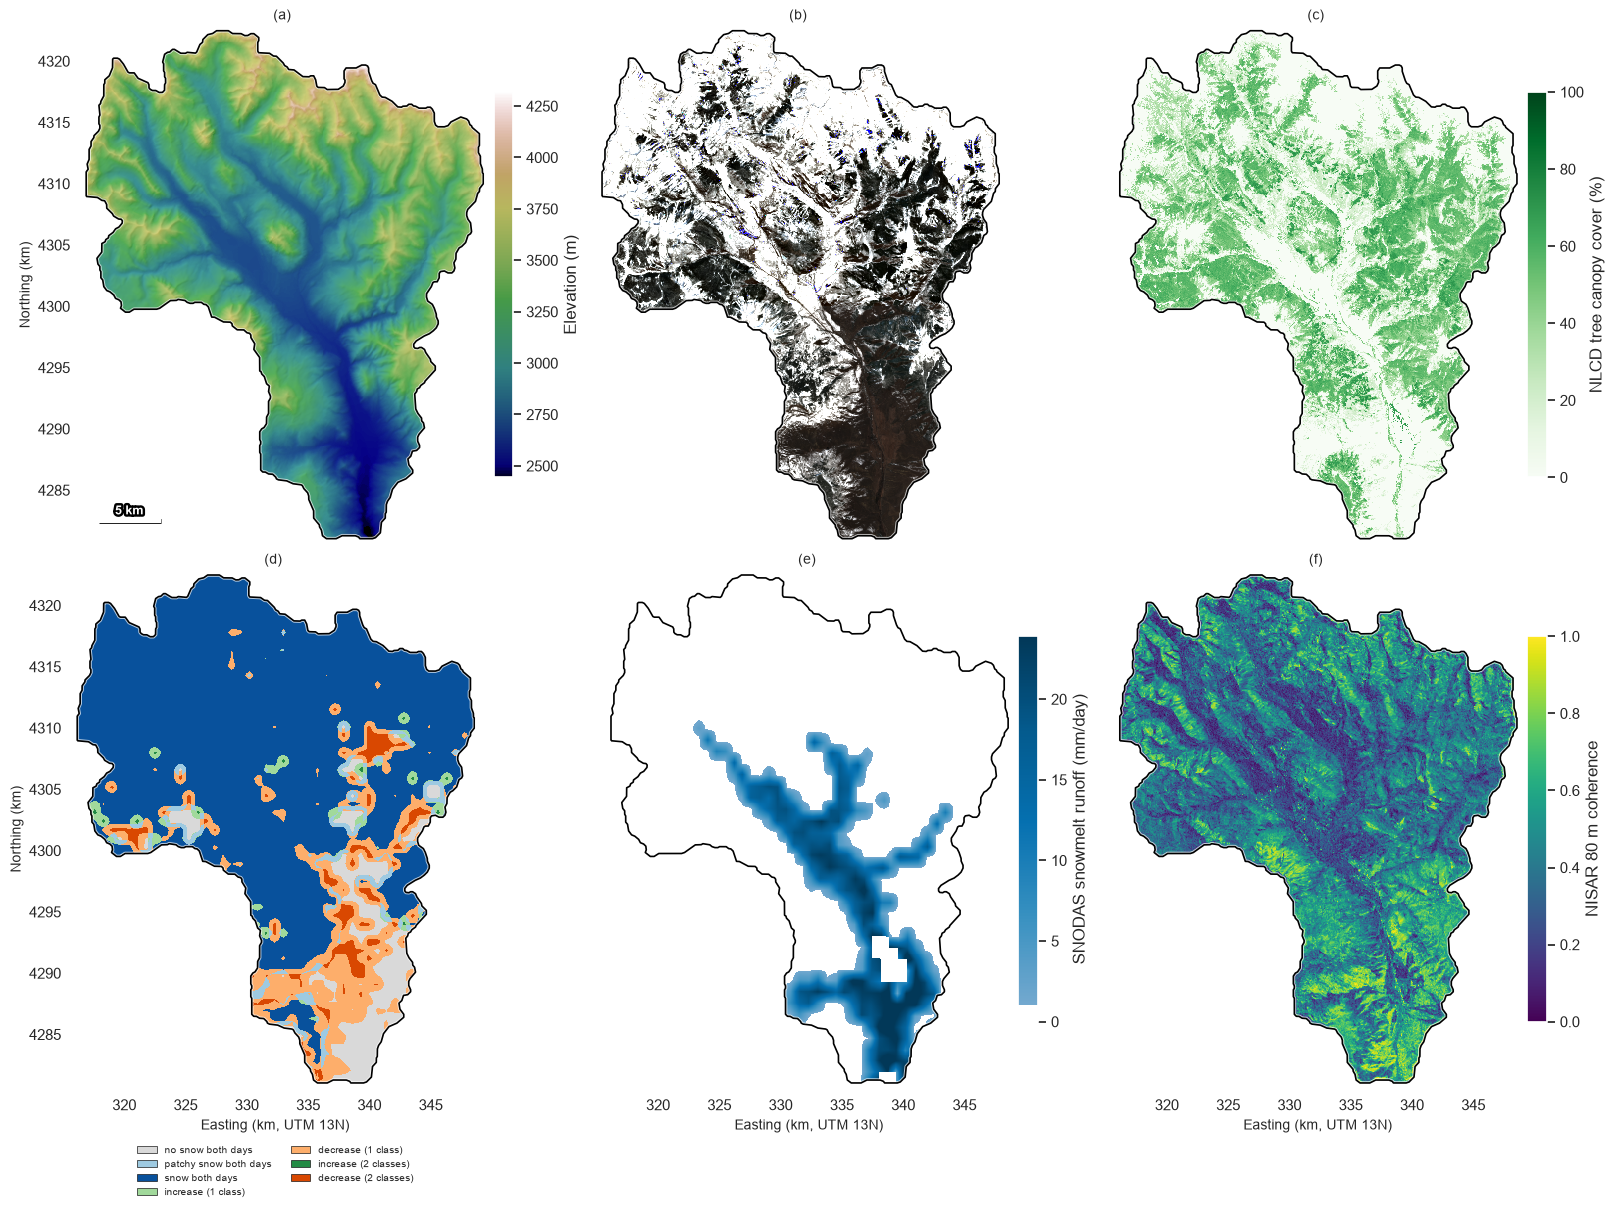

In [32]:
def basin_masked(da):
    return da.where(valid) if MASK_TO_BASIN else da


def plot_figure(savename=None):
    left, bottom, right, top = grid.rio.bounds()
    extent = (left, right, bottom, top)
    cmap_kw = lambda name: plt.get_cmap(name).with_extremes(bad=BLANK_COLOR)

    fig, axes = plt.subplots(NROWS, NCOLS, figsize=FIGSIZE, sharex=True, sharey=True, constrained_layout=True)
    axes = axes.ravel()

    # 1. DEM
    vmin = float(dem.min()) if DEM_VMIN is None else DEM_VMIN
    vmax = float(dem.max()) if DEM_VMAX is None else DEM_VMAX
    shade = hillshade_rgb(dem, DEM_CMAP, vmin, vmax)
    if MASK_TO_BASIN:
        shade = np.where(valid.values[..., None], shade, 1.0)
    axes[0].imshow(shade, extent=extent, origin='upper', interpolation='nearest')
    fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap=DEM_CMAP), ax=axes[0], label=DEM_CBAR_LABEL, **CBAR_KW)

    # 2. Sentinel-2
    img = s2_display(rgb)
    if MASK_TO_BASIN:
        img = np.where(valid.values[..., None], img, 1.0)
    axes[1].imshow(np.where(np.isnan(img), 1.0, img), extent=extent, origin='upper', interpolation='nearest')

    # 3. canopy
    im = axes[2].imshow(basin_masked(canopy).values, extent=extent, origin='upper', cmap=cmap_kw(CANOPY_CMAP), vmin=CANOPY_VMIN, vmax=CANOPY_VMAX, interpolation='nearest')
    fig.colorbar(im, ax=axes[2], label=CANOPY_CBAR_LABEL, **CBAR_KW)

    # 4. fSCA change (categorical, legend instead of a colorbar)
    cmap = ListedColormap(CHANGE_COLORS).with_extremes(bad=BLANK_COLOR)
    chg = basin_masked(snow_change).values
    axes[3].imshow(chg, extent=extent, origin='upper', cmap=cmap, vmin=-0.5, vmax=len(CHANGE_COLORS) - 0.5, interpolation='nearest')
    present = set(np.unique(chg[~np.isnan(chg)]).astype(int))
    codes = [c for c in labels if (c in present or not CHANGE_LEGEND_ONLY_PRESENT)]
    axes[3].legend(handles=[Patch(facecolor=CHANGE_COLORS[c], edgecolor='k', linewidth=0.5, label=labels[c]) for c in codes], **CHANGE_LEGEND_KW)

    # 5. SNODAS
    sv = SNODAS_VARS[SNODAS_VAR]
    data5 = basin_masked(snodas)
    vmax5 = float(np.nanpercentile(data5.values, 99)) if SNODAS_VMAX is None else SNODAS_VMAX
    vmin5 = float(np.nanmin(data5.values)) if SNODAS_VMIN is None else SNODAS_VMIN
    cmap5 = cmap_kw(sv['cmap'])
    if SNODAS_WET_THRESHOLD is not None:
        f = (SNODAS_WET_THRESHOLD - vmin5) / (vmax5 - vmin5)           # threshold as a fraction of the color range
        base = plt.get_cmap(sv['cmap'])
        # sample the real colormap above the threshold so hues stay clean instead of blending two end colors
        wet = [(f + (1 - f) * t, base(SNODAS_WET_START + (1 - SNODAS_WET_START) * t)) for t in np.linspace(0, 1, 256)]
        cmap5 = LinearSegmentedColormap.from_list('wet_dry', [(0, SNODAS_DRY_COLOR), (f, SNODAS_DRY_COLOR)] + wet).with_extremes(bad=BLANK_COLOR)
    im = axes[4].imshow(data5.values, extent=extent, origin='upper', cmap=cmap5, vmin=vmin5, vmax=vmax5, interpolation='nearest')
    fig.colorbar(im, ax=axes[4], label=sv['label'], **CBAR_KW)

    # 6. coherence
    im = axes[5].imshow(basin_masked(coh).values, extent=extent, origin='upper', cmap=cmap_kw(COH_CMAP), vmin=COH_VMIN, vmax=COH_VMAX, interpolation='nearest')
    fig.colorbar(im, ax=axes[5], label=COH_CBAR_LABEL, **CBAR_KW)

    for i, ax in enumerate(axes):
        finish(ax, i, extent)
    for ax in axes:                                     # only outer panels carry axis labels
        ax.set_xlabel('')
        ax.set_ylabel('')
    for ax in axes[-NCOLS:]:
        ax.set_xlabel('Easting (km, UTM 13N)' if AXIS_KM else 'Easting (m)')
    for ax in axes[::NCOLS]:
        ax.set_ylabel('Northing (km)' if AXIS_KM else 'Northing (m)')

    if SAVE_FIGS and savename:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir + savename, dpi=FIG_DPI, bbox_inches='tight')
    plt.show()


plot_figure(savename=FIG_NAME)

# Save the aligned layers

Write the 80 m layers used in the figure to one Zarr and to a GeoTIFF per layer, for quick checks in a GIS.

In [25]:
if SAVE_LAYERS:
    layers = xr.Dataset({
        'dem': dem,
        'canopy': canopy,
        'snow_change': snow_change,
        'snodas': snodas,
        'coherence': coh,
    })
    layers = layers.drop_vars([c for c in ('pair', 'start', 'end', 'time', 'band') if c in layers.coords])
    layers['sentinel2'] = rgb.assign_coords(band=list(S2_BANDS))
    layers.attrs = dict(pair=PAIR, s2_date=S2_DATE, snodas_date=SNODAS_DATE, snodas_var=SNODAS_VAR, change_labels=str(labels))
    layers.to_zarr(LAYERS_ZARR, mode='w')
    Path(LAYERS_TIF_DIR).mkdir(parents=True, exist_ok=True)
    for name, da in layers.data_vars.items():
        da.astype('float32').rio.write_crs(crs).rio.to_raster(LAYERS_TIF_DIR + f'{name}.tif')
    logging.info(f"Wrote {LAYERS_ZARR} and {len(layers.data_vars)} GeoTIFFs to {LAYERS_TIF_DIR}")

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=3, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
2026-10-28 11:11:56,514 - INFO - Wrote ../